Notes: needs cleanup, just moving for now to ensure it runs

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from dataclasses import dataclass
import os
import sys
sys.path.append("/code")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
import seaborn as sns

import bg_spatial_plots.plot_spatial_histograms as histplot
from bg_spatial_plots.constants_color_palettes import CURRENT_COLOR_DICT_OF_DICTS
from bg_spatial_plots.figure_utils import plot_spatial_subset, add_scalebar, highlight_clusters_cmap
from bg_spatial_plots.gradient_utils import plot_pc_on_single_plane, project_2d_points_to_line, find_best_gradient_pc
from bg_spatial_plots.coordinate_transforms import add_centered_rotated_coords_marmoset

#from bg_spatial_plots.pca_utils import plot_pc_on_spatial_axes

plt.rcParams['font.family'] = 'sans-serif'  # Set font family (e.g., 'serif', 'sans-serif', 'monospace')
plt.rcParams['font.serif'] = ['Arial'] # Specify a particular serif font
plt.rcParams['font.size'] = 6  # Set default font size
plt.rcParams['font.weight'] = 'normal' # Set font weight (e.g., 'bold', 'normal')

from bg_spatial_plots.gradient_contours import smooth_field, SpeciesContours, compute_shared_levels, draw_section_contour, plot_contours_all_sections, plot_clusters_with_contours, plot_cluster_contour_barplot

In [2]:
def plot_pc_on_spatial_axes(
    adata,
    spatial_keys=("x_slab_um", "y_slab_um"),
    z_key="z_order",
    pc_index=0,
    top_n_genes=10,
    marker_size=0.1,
    cmap="RdBu_r",
    invert_y=True,
    ncols=None,
    panel_width=5.0,
    panel_height=4.4,
    figsize=None,
    colorbar=True,
    colorbar_location="right",
    colorbar_fraction=0.046,
    colorbar_pad=0.02,
    colorbar_aspect=30,
    colorbar_label=None,
    share_axes=True,
    constrained_layout=True,
    fig=None,
    axes=None,
    show=False,
):
    pc_scores = adata.obsm["X_pca"][:, pc_index]
    adata.obs[f"PC_{pc_index}"] = pc_scores
    vlim_abs = np.nanmax(np.abs(pc_scores))

    sections = sorted(adata.obs[z_key].unique())
    n = len(sections)
    ncols = ncols or min(n, 3)
    nrows = int(np.ceil(n / ncols))

    if axes is None:
        figsize = figsize or (panel_width * ncols, panel_height * nrows)
        fig, axes = plt.subplots(
            nrows, ncols, figsize=figsize, squeeze=False,
            sharex=share_axes, sharey=share_axes,
            constrained_layout=constrained_layout,
        )
    else:
        axes = np.atleast_2d(axes)
        fig = fig or axes.flat[0].figure

    flat = axes.ravel()
    sc_plot = None
    for (i, section), ax in zip(enumerate(sections), flat):
        ad_sec = adata[adata.obs[z_key] == section]
        sc_plot = plot_pc_on_single_plane(ad_sec, spatial_keys, pc_index, vlim_abs,
                                          ax, marker_size, cmap, invert_y=False)
        ax.set_aspect("equal")

    for ax in flat[n:]:
        ax.axis("off")

    if colorbar and sc_plot is not None:
        fig.colorbar(sc_plot, ax=axes, location=colorbar_location,
                     fraction=colorbar_fraction, pad=colorbar_pad,
                     aspect=colorbar_aspect, label=colorbar_label or f"PC{pc_index} score")

    if invert_y:
        if share_axes:
            flat[0].invert_yaxis()
        else:
            for ax in flat[:n]:
                ax.invert_yaxis()

    if top_n_genes:
        def get_top_pc_genes(adata, pc_index, top_n=10):
            loadings = adata.varm["PCs"][:, pc_index]
            top_pos_idx = loadings.argsort()[::-1][:top_n]
            top_neg_idx = loadings.argsort()[:top_n]
            return adata.var_names[top_pos_idx], adata.var_names[top_neg_idx]
        top_pos_genes, top_neg_genes = get_top_pc_genes(adata, pc_index, top_n_genes)
        print(f"\nPC{pc_index} Top Positive Genes: {', '.join(top_pos_genes)}")
        print(f"PC{pc_index} Top Negative Genes: {', '.join(top_neg_genes)}")

    if show:
        plt.show()
    return fig, axes

### Set per-section parameters and globals

In [3]:
@dataclass
class SectionParams:
    z: int
    xlims: tuple
    ylims: tuple
    p1: np.ndarray          # axis line start
    p2: np.ndarray          # axis line end

    def get_barcode(self, adata):
        return str(adata.obs.loc[adata.obs["z_order"] == self.z, "brain_section_barcode"].iloc[0])

SECTIONS = {
    "anterior": {
        "marmoset": SectionParams(z=11, xlims=(750, 5250),   ylims=(900, 4900),
                                  p1=np.array([500, -13500]),  p2=np.array([6000, -7000])),  # TODO: fix line with new coords
        "macaque":  SectionParams(z=7,  xlims=(38500, 46500), ylims=(36000, 29000),
                                  p1=np.array([38000, 36000]), p2=np.array([50000, 22000])),
        "human":    SectionParams(z=7,  xlims=(13500, 29500), ylims=(86000, 71000),
                                  p1=np.array([12000, 88000]), p2=np.array([32000, 63000])),
    },
    "posterior": {
        "marmoset": SectionParams(z=24, xlims=(2000, 5100),   ylims=(-250, 2250),
                                  p1=np.array([4750, -12500]), p2=np.array([8000, -11000])),  # TODO: fix line with new coords
        "macaque":  SectionParams(z=16, xlims=(45000, 55000), ylims=(40000, 30000),
                                  p1=np.array([46000, 37500]), p2=np.array([55000, 35000])),
        "human":    SectionParams(z=16, xlims=(20500, 33500), ylims=(95500, 82500),
                                  p1=np.array([22500, 87000]), p2=np.array([32000, 87000])),
    },
    "posterior_alt": {
        "marmoset": SectionParams(z=23, xlims=(2000, 5100),   ylims=(-250, 2250),
                                  p1=np.array([4750, -12500]), p2=np.array([8000, -11000])),  # TODO: fix line with new coords
        "macaque":  SectionParams(z=15, xlims=(46000, 55000), ylims=(39000, 33000),
                            p1=np.array([46000, 37500]), p2=np.array([55000, 35000])),
        "human":    SectionParams(z=15, xlims=(20500, 33500), ylims=(95500, 82500),
                            p1=np.array([22500, 87000]), p2=np.array([32000, 87000])),
    }
}

XCOL, YCOL = "x_slab_um", "y_slab_um"
group_color_dict = CURRENT_COLOR_DICT_OF_DICTS["Group"]
group_color_dict["Adjacent"] = "#D3D3D3"

In [4]:
# inspect and see what's in there, if we still need to load our own data, etc.
adata_hum = ad.read_h5ad('/data/SPNs_with_PCA_batch_log1p/Human_SPNs_with_PCA_batch_log.h5ad')
adata_mac = ad.read_h5ad('/data/SPNs_with_PCA_batch_log1p/Macaque_SPNs_with_PCA_batch_log.h5ad')
adata_marm = ad.read_h5ad('/data/SPNs_with_PCA_batch_log1p/Marmoset_SPNs_with_PCA_batch_log.h5ad')

# brian doesn't have the aligned coords in his file, so we will add it ourselves
if 'x_rotated_aligned' not in adata_marm.obs.columns or 'y_rotated_aligned' not in adata_marm.obs.columns:
    print('Aligning rotated coordinates across sections for marmoset...')
    add_centered_rotated_coords_marmoset(adata_marm, inplace=True)

adata_marm.obs['x_slab_um'] = adata_marm.obs['x_rotated_centered_um']
adata_marm.obs['y_slab_um'] = adata_marm.obs['y_rotated_centered_um']

Aligning rotated coordinates across sections for marmoset...


(np.float64(459.015478515625),
 np.float64(6860.674951171875),
 np.float64(548.4059570312498),
 np.float64(8283.47490234375))

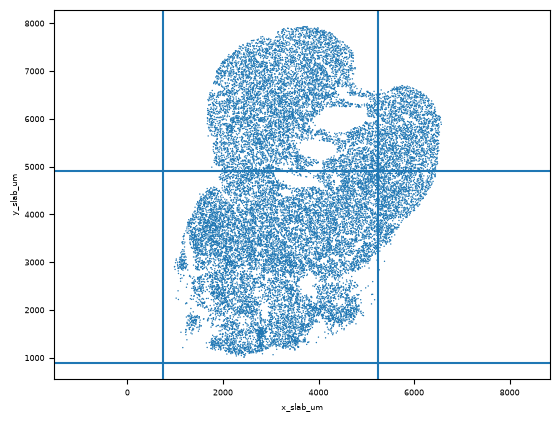

In [5]:
sns.scatterplot(adata_marm.obs[adata_marm.obs['z_order'] == 11], x='x_slab_um', y='y_slab_um', s=1, edgecolor='none')

plt.axvline(750)
plt.axvline(5250)
plt.axhline(4900)
plt.axhline(900)
plt.axis('equal')

(np.float64(-920.2283203125),
 np.float64(5386.6775390625),
 np.float64(-638.4458740234375),
 np.float64(7907.363354492188))

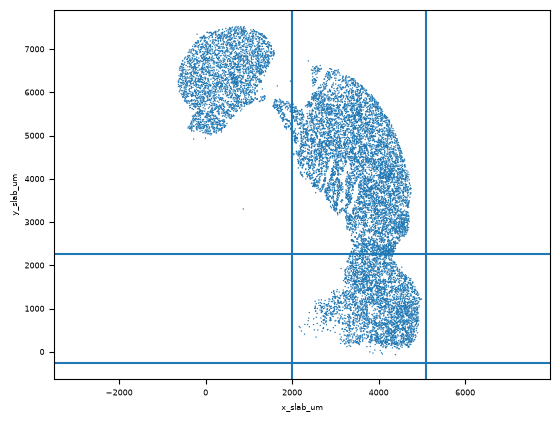

In [6]:
sns.scatterplot(adata_marm.obs[adata_marm.obs['z_order'] == 23], x='x_slab_um', y='y_slab_um', s=1, edgecolor='none')

plt.axvline(2000)
plt.axvline(5100)
plt.axhline(-250)
plt.axhline(2250)
plt.axis('equal')


PC1 Top Positive Genes: SPOCK1, SCN4B, TESPA1, JCAD, GPRIN3, LOC100385731, CNR1, FAM135B, PPP1R1B, LMO1
PC1 Top Negative Genes: PLCXD3, ST6GALNAC5, CSGALNACT1, GLRA3, CCDC85A, GULP1, SYT10, ABLIM1, GDA, MPPED1

PC1 Top Positive Genes: GDA, NELL1, CSGALNACT1, BRINP3, PRKG1, DPP10, HTR2C, GULP1, MOXD1, SEMA3E
PC1 Top Negative Genes: COL25A1, PMFBP1, HPCA, TESPA1, CNR1, SNTG2, MME, KCTD17, CHRM3, SYT2

PC1 Top Positive Genes: ARHGAP6, GDA, SLC35F1, MEIS3, LINGO2, PDE1C, RGS6, KCTD12, LYPD1, KCNIP1
PC1 Top Negative Genes: TESPA1, PDE10A, CHRM3, LOXHD1, NEFM, CNR1, ADORA2A, LPL, TUNAR, COL5A3


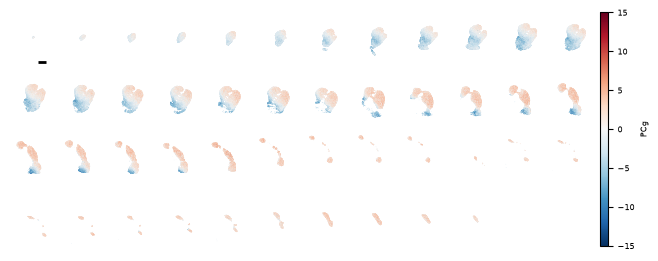

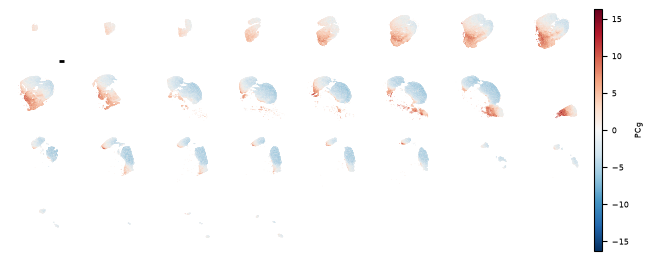

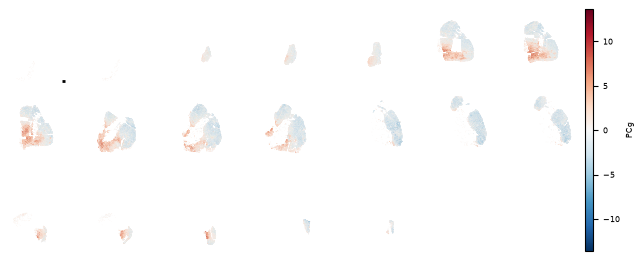

In [7]:
H = 2.5
fig_marm, _ = plot_pc_on_spatial_axes(adata_marm, pc_index=1, figsize=(6.5, H), ncols=12, colorbar_label="PCg", invert_y=False)
fig_mac,  _ = plot_pc_on_spatial_axes(adata_mac,  pc_index=1, figsize=(6.5, H), ncols=8, colorbar_label="PCg")
fig_hum,  _ = plot_pc_on_spatial_axes(adata_hum,  pc_index=1, figsize=(6.5, H), ncols=7, colorbar_label="PCg")

add_scalebar(fig_marm.axes[0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
add_scalebar(fig_mac.axes[0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
add_scalebar(fig_hum.axes[0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))

In [8]:
# select the gradient PCs based on correlation + qualitative appearance
marm_pc_index = 2
mac_pc_index = 2
hum_pc_index = 2

marm_pgcv = f'PC_{marm_pc_index}'
mac_pgcv = f'PC_{mac_pc_index}'
hum_pgcv = f'PC_{hum_pc_index}'

# flip the sign of the human PC IF NEEDED to match the others
adata_hum.obs[hum_pgcv] = -adata_hum.obs[hum_pgcv]
adata_hum.obsm['X_pca'][:, 1] = -adata_hum.obsm['X_pca'][:, 1]

adata_mac.obs[mac_pgcv] = -adata_mac.obs[mac_pgcv]
adata_mac.obsm['X_pca'][:, 1] = -adata_mac.obsm['X_pca'][:, 1]


PC1 Top Positive Genes: SPOCK1, SCN4B, TESPA1, JCAD, GPRIN3, LOC100385731, CNR1, FAM135B, PPP1R1B, LMO1
PC1 Top Negative Genes: PLCXD3, ST6GALNAC5, CSGALNACT1, GLRA3, CCDC85A, GULP1, SYT10, ABLIM1, GDA, MPPED1

PC1 Top Positive Genes: GDA, NELL1, CSGALNACT1, BRINP3, PRKG1, DPP10, HTR2C, GULP1, MOXD1, SEMA3E
PC1 Top Negative Genes: COL25A1, PMFBP1, HPCA, TESPA1, CNR1, SNTG2, MME, KCTD17, CHRM3, SYT2

PC1 Top Positive Genes: ARHGAP6, GDA, SLC35F1, MEIS3, LINGO2, PDE1C, RGS6, KCTD12, LYPD1, KCNIP1
PC1 Top Negative Genes: TESPA1, PDE10A, CHRM3, LOXHD1, NEFM, CNR1, ADORA2A, LPL, TUNAR, COL5A3


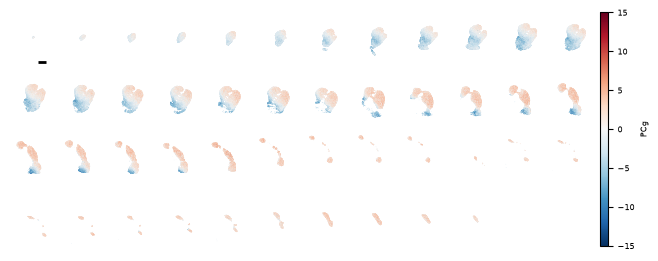

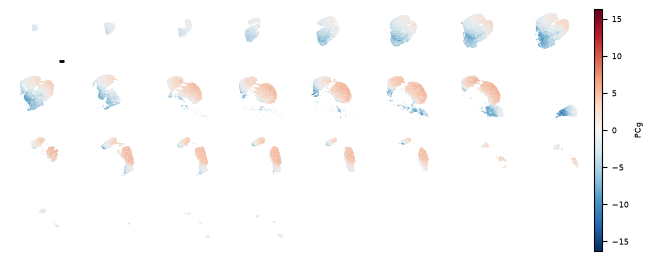

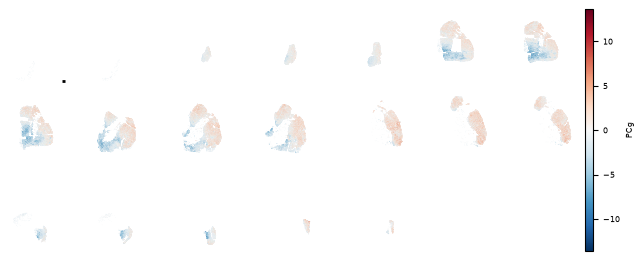

In [9]:
H = 2.5
fig_marm, _ = plot_pc_on_spatial_axes(adata_marm, pc_index=1, figsize=(6.5, H), ncols=12, colorbar_label="PCg", invert_y=False)
fig_mac,  _ = plot_pc_on_spatial_axes(adata_mac,  pc_index=1, figsize=(6.5, H), ncols=8, colorbar_label="PCg")
fig_hum,  _ = plot_pc_on_spatial_axes(adata_hum,  pc_index=1, figsize=(6.5, H), ncols=7, colorbar_label="PCg")

add_scalebar(fig_marm.axes[0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
add_scalebar(fig_mac.axes[0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
add_scalebar(fig_hum.axes[0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))

for f, name in [(fig_marm,"marm"),(fig_mac,"mac"),(fig_hum,"hum")]:
    f.savefig(f"/results/pc_spatial_{name}.svg", dpi=600)

### All section contour plots

Might go in a supplemental figure

Lots of tunable parameters though:
- sigma_um
- margin_um
- level_mode

Might be worth testing a few to get the best results.

In [10]:
# ok something with this stuff still needs to be fixed
marm_pgcv = f'PC_{marm_pc_index-1}'
mac_pgcv = f'PC_{mac_pc_index-1}'
hum_pgcv = f'PC_{hum_pc_index-1}'

/code/bg_spatial_plots/gradient_contours.py:111: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for sec_id, data in adata.obs.groupby(sec_col):


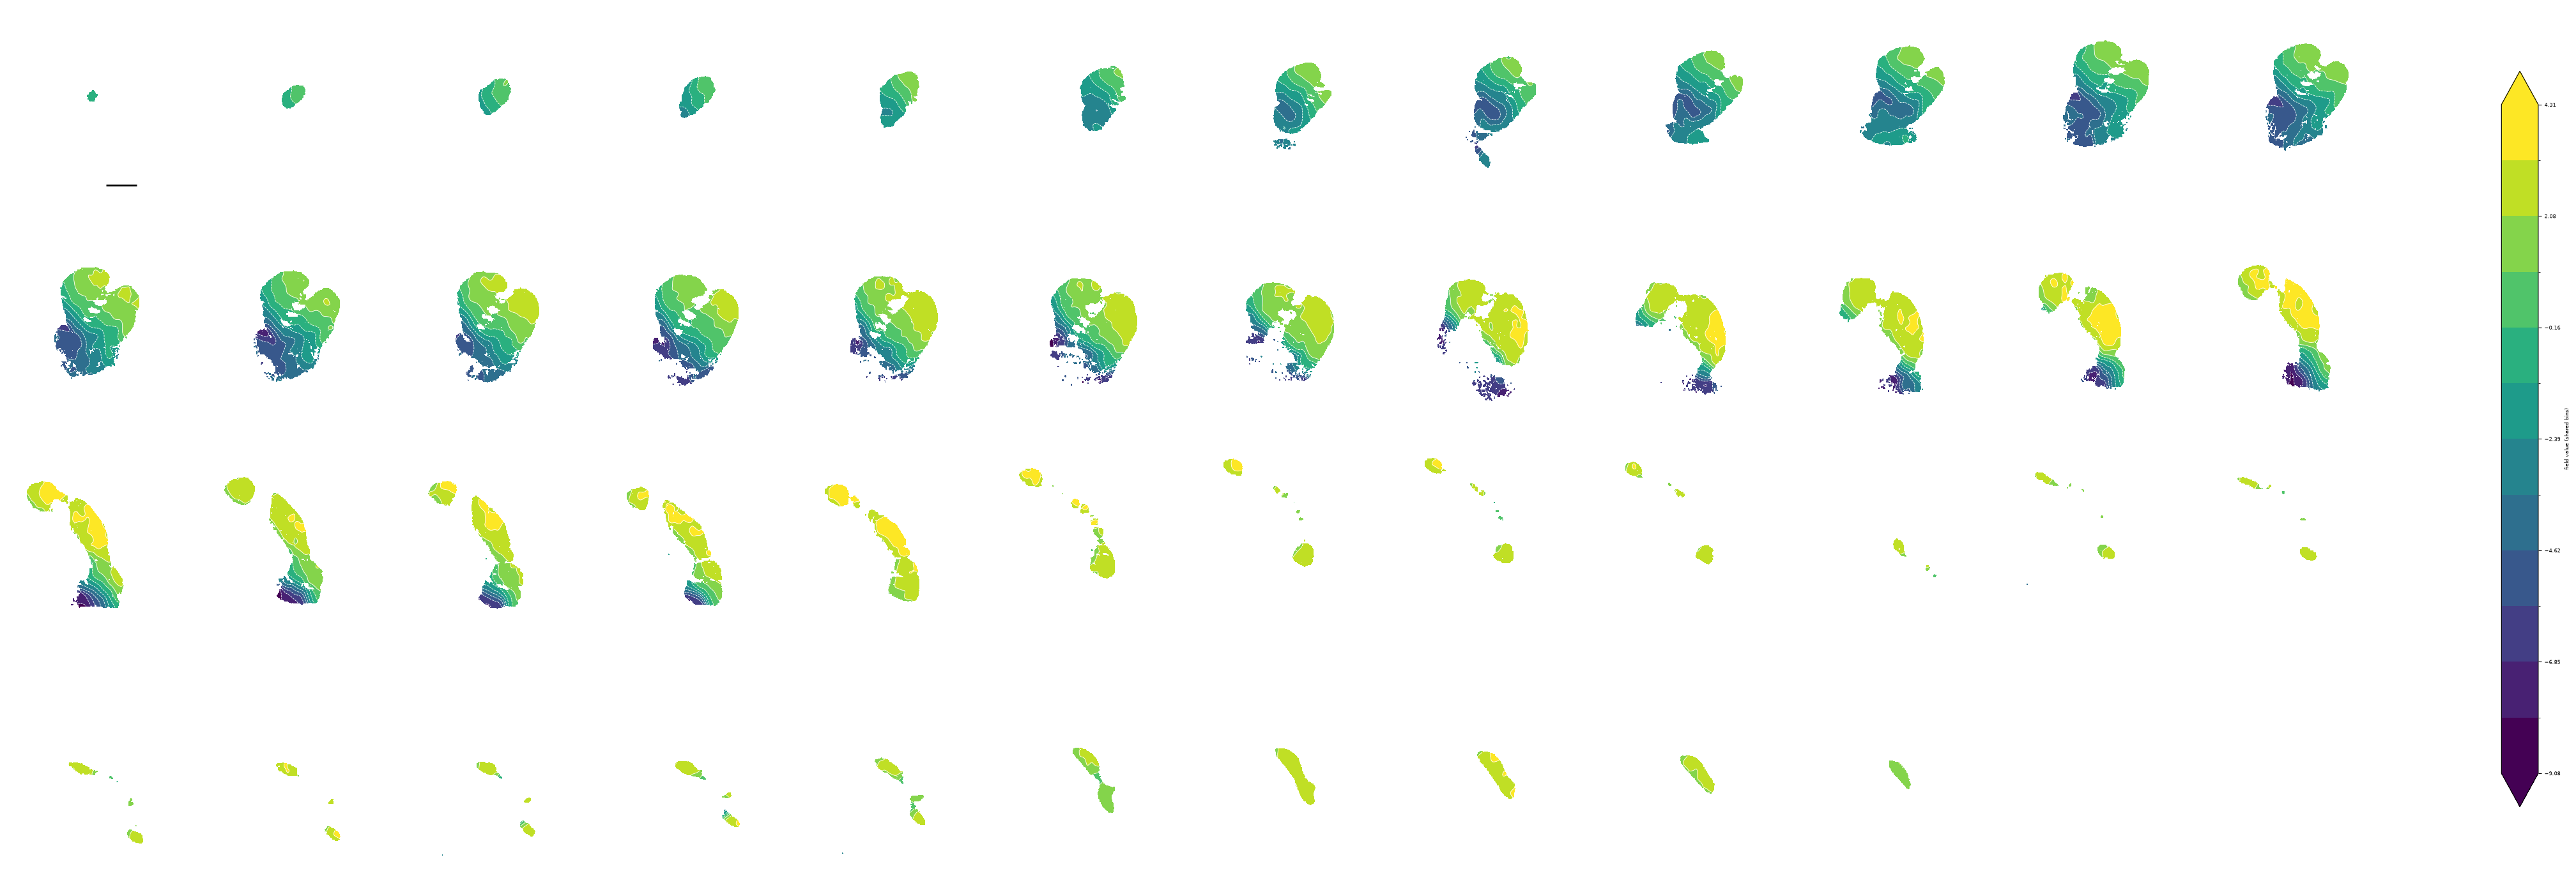

In [11]:
species_adata = {"marmoset": adata_marm, "macaque": adata_mac, "human": adata_hum}
sigma_um_by_species = {"marmoset": 150, "macaque": 300, "human": 600}
margin_um_by_species = {'marmoset': 50, 'macaque': 100, 'human': 200}
pgcv_by_species = {"marmoset": marm_pgcv, 'macaque': mac_pgcv, 'human': hum_pgcv}

contours = {
    sp: compute_shared_levels(ad, pgcv_by_species[sp], margin_um=margin_um_by_species[sp],
                              sigma_um=sigma_um_by_species[sp])
    for sp, ad in species_adata.items()
}

# all sections for one species
fig, axes = plot_contours_all_sections(contours["marmoset"], ncols=12)
for ax in axes.ravel():
    ax.axis('off')
add_scalebar(axes[0,0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
plt.savefig('/results/marmoset_contours.svg')

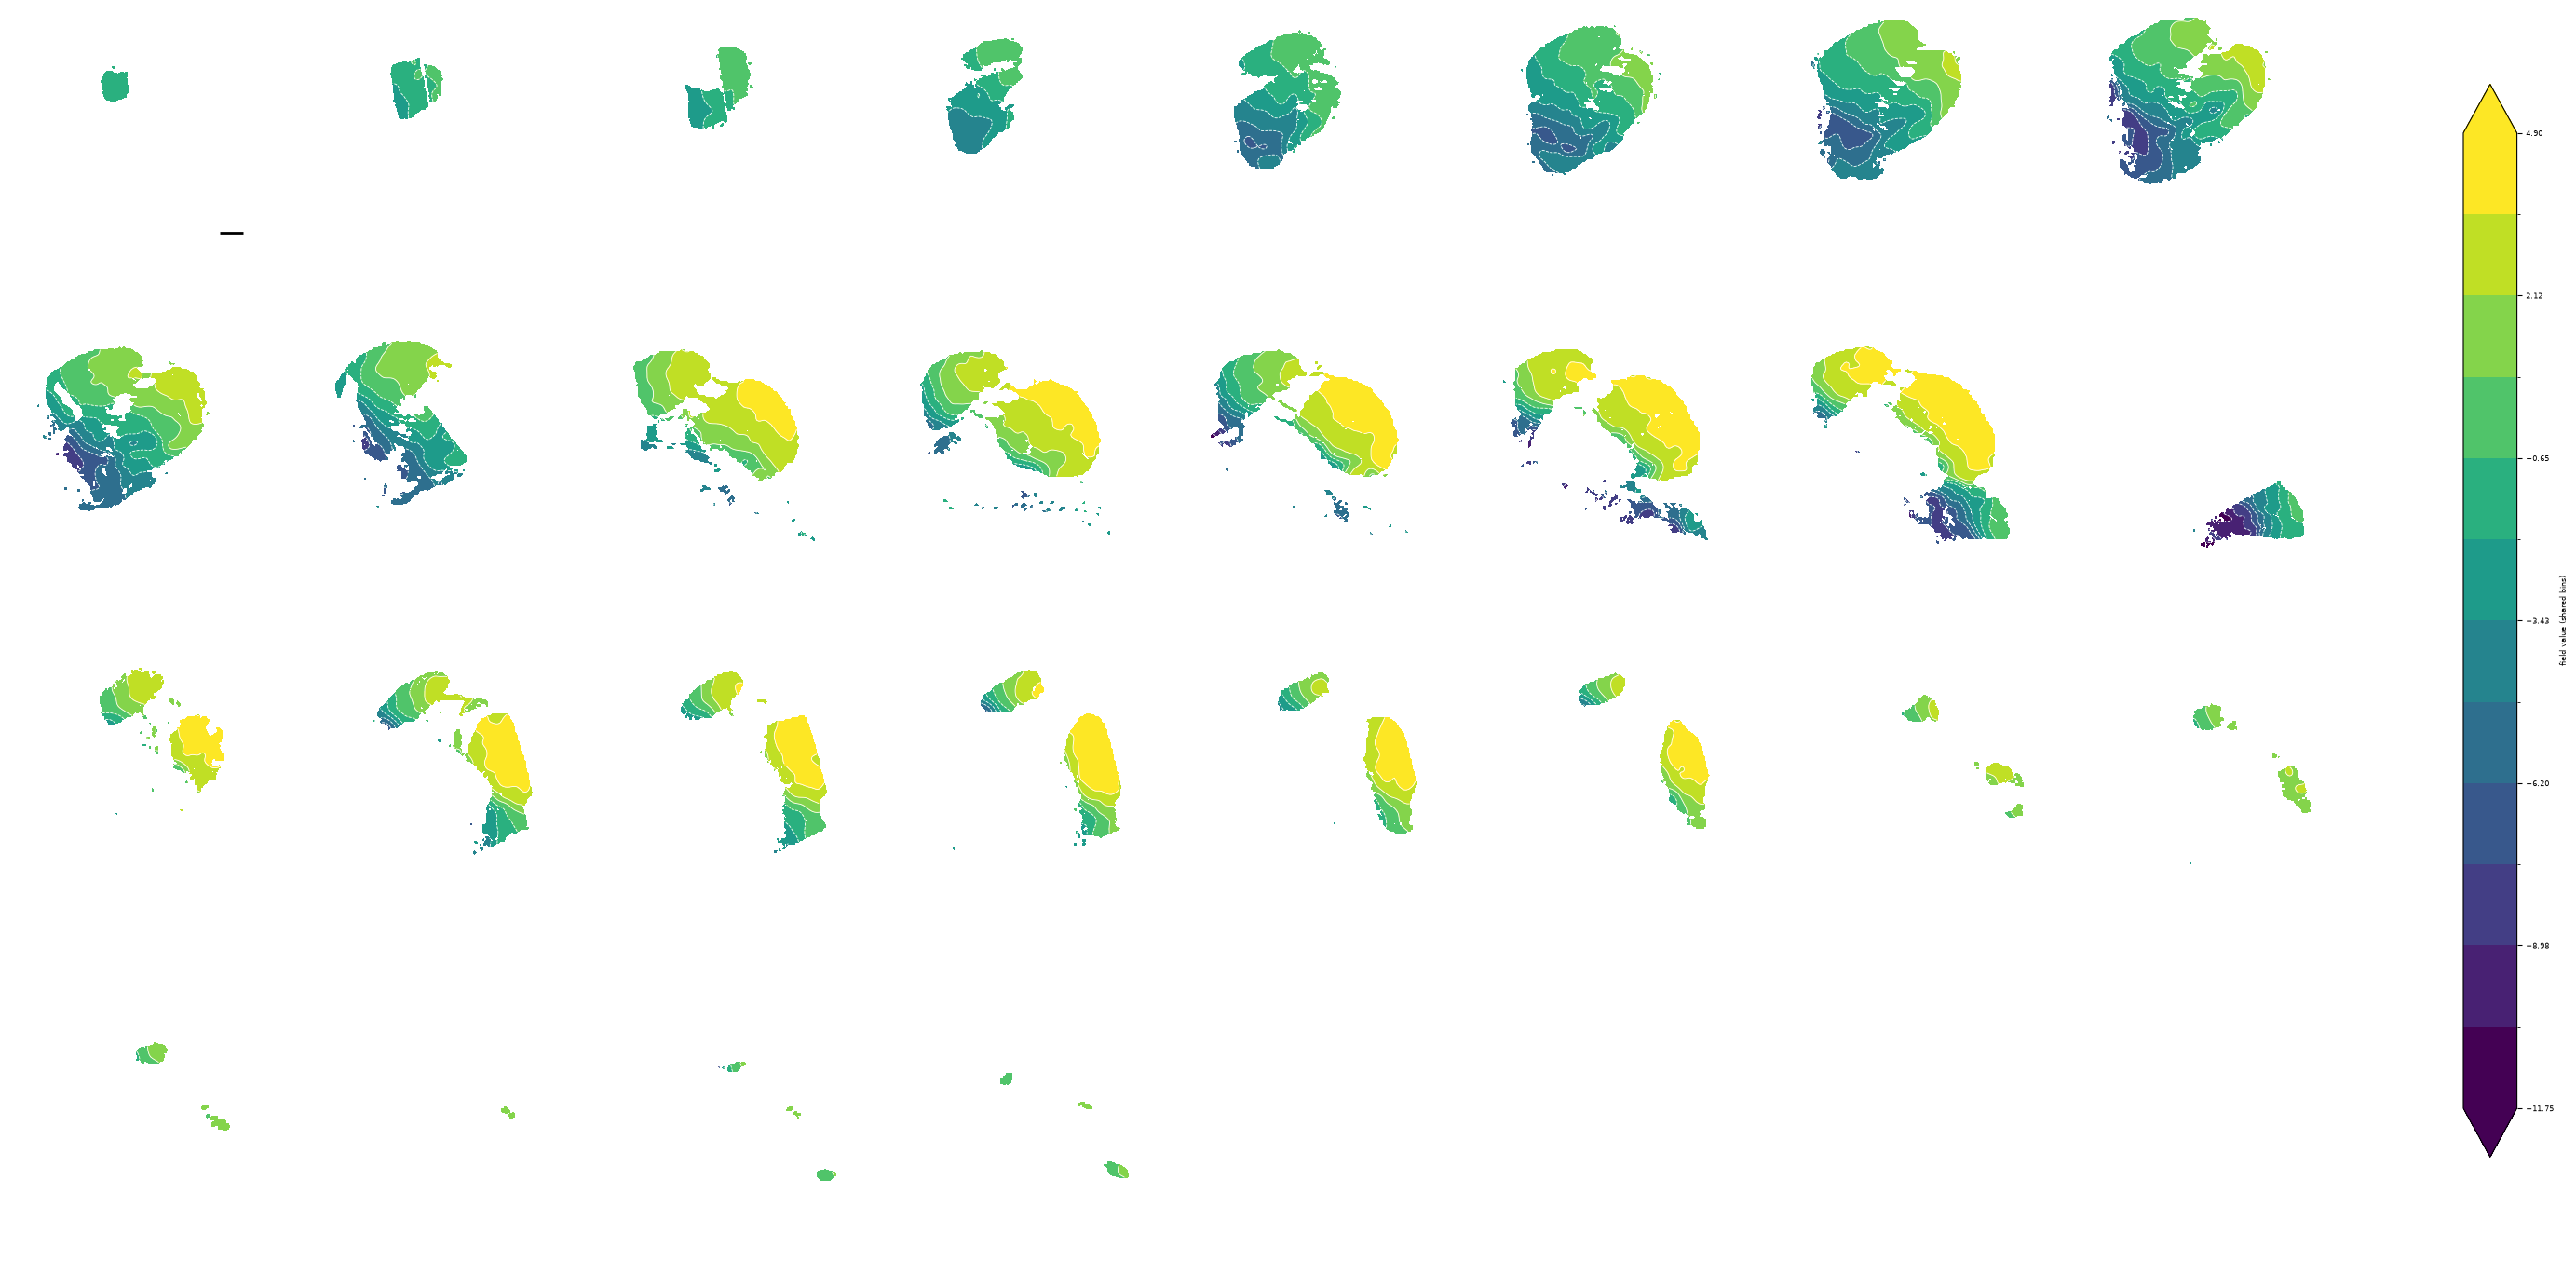

In [12]:
fig, axes = plot_contours_all_sections(contours["macaque"], ncols=8)
axes[0,0].invert_yaxis()
for ax in axes.ravel():
    ax.axis('off')
add_scalebar(axes[0,0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
plt.savefig('/results/macaque_contours.svg')

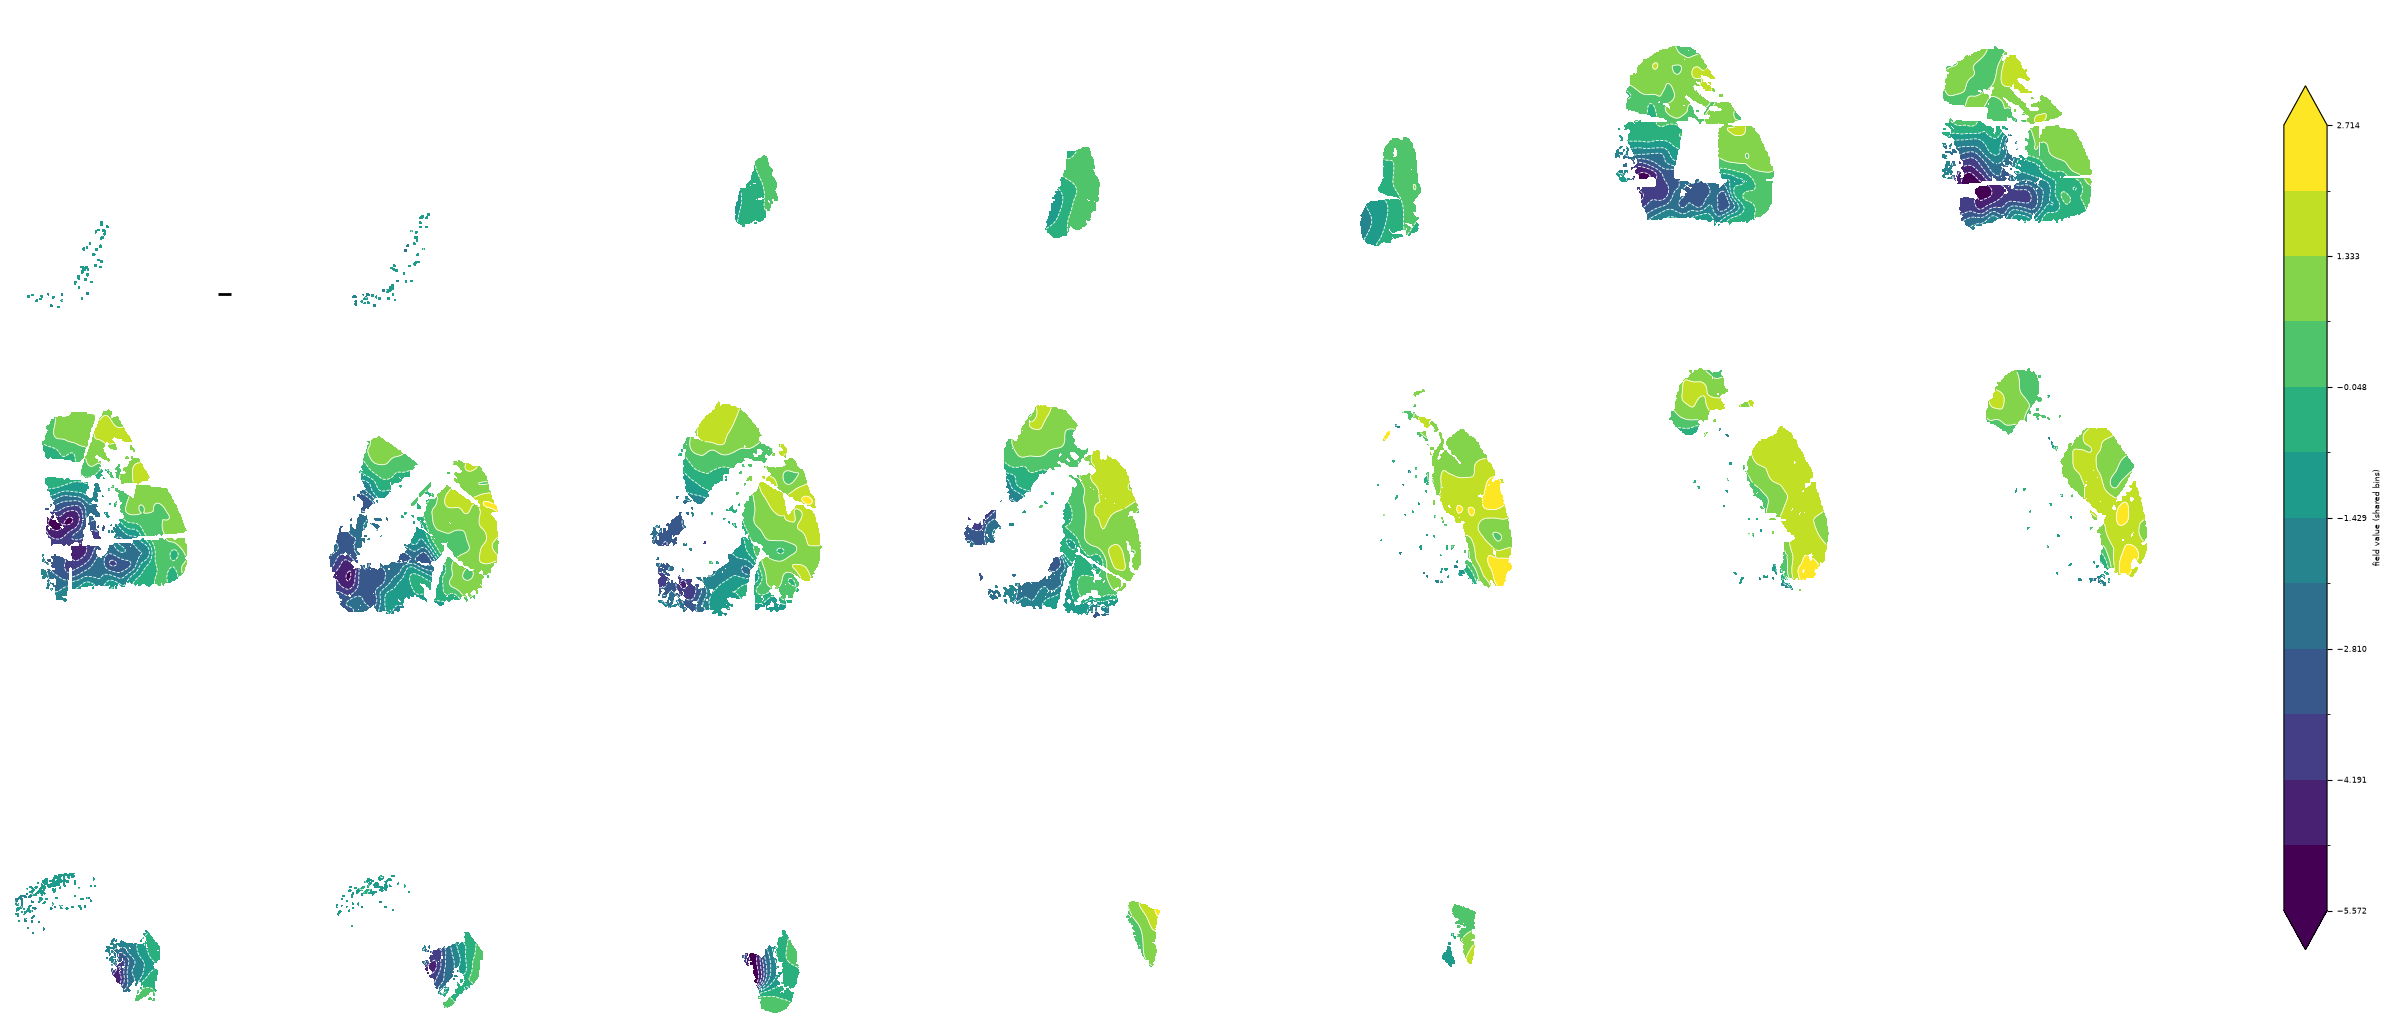

In [13]:
fig, axes = plot_contours_all_sections(contours["human"], ncols=7)
axes[0,0].invert_yaxis()
for ax in axes.ravel():
    ax.axis('off')
add_scalebar(axes[0,0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
plt.savefig('/results/human_contours.svg')

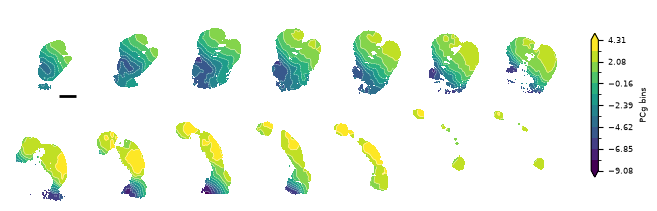

In [14]:
# for figure 4
bundle = contours['marmoset']
z_planes = list(range(7, 34, 2))
z_planes = [z for z in z_planes if z in bundle.grids]

ncols = 7
nrows = int(np.ceil(len(z_planes) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(6.5, 2), squeeze=False, sharex=True, sharey=True, layout='constrained')

for ax, z in zip(axs.ravel(), z_planes):
    cf = draw_section_contour(ax, bundle, sec_id=z, title=f'z={z}', contour_lw=0.3)

for ax in axs.ravel():
    ax.axis('off')
add_scalebar(axs[0,0], matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
#plt.tight_layout()
fig.colorbar(cf, ax=axs, shrink=0.75, label='PCg bins')

# Make svgs

In [15]:
adatas = {'marmoset': adata_marm, 'macaque': adata_mac, 'human': adata_hum}

for section_name, species_params in SECTIONS.items():
    col = f'proj_lengths_{section_name}'
    for species, p in species_params.items():
        adata = adatas[species]
        adata.obs[col] = project_2d_points_to_line(
            adata.obs.loc[:, [XCOL, YCOL]].values, p.p1, p.p2
        )

        print(species)
        print(find_best_gradient_pc(adata.obsm['X_pca'], adata.obs[col]))

for sp, ad in adatas.items():
    contours[sp].assign_to_obs(ad, col='contour_coord', bin_col='contour_bin')

marmoset
PC2 (index: 1) has the highest correlation to projected depth: 0.575
1
macaque
PC2 (index: 1) has the highest correlation to projected depth: 0.799
1
human
PC2 (index: 1) has the highest correlation to projected depth: 0.566
1
marmoset
PC2 (index: 1) has the highest correlation to projected depth: 0.435
1
macaque
PC2 (index: 1) has the highest correlation to projected depth: 0.616
1
human
PC2 (index: 1) has the highest correlation to projected depth: 0.408
1
marmoset
PC2 (index: 1) has the highest correlation to projected depth: 0.435
1
macaque
PC2 (index: 1) has the highest correlation to projected depth: 0.616
1
human
PC2 (index: 1) has the highest correlation to projected depth: 0.408
1


In [16]:
def make_D1_D2_adata(adata_marm_subset, groups=None):
    if groups:
        adata_marm_D1_D2 = adata_marm_subset[adata_marm_subset.obs['Group'].isin(groups)].copy()
    else:
        adata_marm_D1_D2 = adata_marm_subset.copy()
    adata_marm_D1_D2.obs['D1'] = adata_marm_D1_D2.obs['Subclass'] == 'STR D1 SPN'
    adata_marm_D1_D2.obs['D2'] = adata_marm_D1_D2.obs['Subclass'] == 'STR D2 SPN'
    adata_marm_D1_D2.obs['D1_or_D2'] = np.where(adata_marm_D1_D2.obs['D1'], 'D1', 'D2')
    adata_marm_D1_D2.obs['D1_or_D2'] = adata_marm_D1_D2.obs['D1_or_D2'].astype('category')
    adata_marm_D1_D2.obs.loc[:, ['Group', 'D1', 'D2', 'D1_or_D2']]
    return adata_marm_D1_D2

def plot_histogram_wrapper(ax, adata, z, bin_size, imshow_size=None, obs_field='D1_or_D2',
                           cat='D2', cmap='PiYG_r', obsm_key='spatial_slab_um', groups=None):
    adata_sec = adata[adata.obs['z_order'] == z].copy()
    adata_sec = make_D1_D2_adata(adata_sec, groups=groups)
    H, xe, ye = histplot.calculate_2D_histogram(
        adata_sec, coords_obsm_key=obsm_key, obs_field=obs_field,
        category=cat, binsize=bin_size, normalization='proportion')
    return histplot.plot_2D_histogram(
        H, xe, ye, title=None, ax=ax, cmap=cmap, vlims=(0, 1),
        imshow_size=imshow_size,                 # None -> draws at true micron extent
        highlight_zero=True, normalization='proportion', show_legend=False,
        show_cbar=False, return_im=True)

for sp, ad in adatas.items():
    ad.obsm['spatial_slab_um'] = ad.obs[['x_slab_um', 'y_slab_um']].to_numpy()

hist_params = {
    'marmoset': {'bin_size': 100, 'obsm_key': 'spatial_slab_um'},
    'macaque':  {'bin_size': 200, 'obsm_key': 'spatial_slab_um'},
    'human':    {'bin_size': 400, 'obsm_key': 'spatial_slab_um'},
}

def plot_clusters(ax, adata, z, clusters, palette, fg_kwargs, bg_kwargs, xlims, ylims):
    cmap = highlight_clusters_cmap(adata['Cluster'].unique(), clusters, palette)
    plot_spatial_subset(data=adata, xcol='x_slab_um', ycol='y_slab_um', zcol_name='z_order', zcol_val=z, fg_col='Cluster', fg_vals=clusters, fg_kwargs=fg_kwargs, bg_kwargs=bg_kwargs, palette=cmap, ax=ax)
    #add_colored_text_labels(ax, {k: v for k, v in cmap.items() if k in clusters})
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)


In [17]:
CLUSTER_GROUPS = {
    "anterior": {
        "marmoset": {"Marmoset-95": sns.color_palette('tab10')[0]},
        "macaque":  {"Macaque-9": sns.color_palette('tab10')[0], "Macaque-10": sns.color_palette('tab10')[1]},
        "human":    {"Human-215": sns.color_palette('tab10')[1], "Human-216": sns.color_palette('tab10')[0]},
    },
    "posterior": {
        "marmoset": {"Marmoset-996": sns.color_palette('tab10')[3], "Marmoset-1008": sns.color_palette('tab10')[4],
                     "Marmoset-1012": sns.color_palette('tab10')[6], "Marmoset-1007": sns.color_palette('tab10')[2],
                     "Marmoset-1006": sns.color_palette('tab10')[5]},
        "macaque":  {"Macaque-406": sns.color_palette('tab10')[2], "Macaque-407": sns.color_palette('tab10')[3]},
        "human":    {"Human-332": sns.color_palette('tab10')[2], "Human-335": sns.color_palette('tab10')[4],
                     "Human-508": sns.color_palette('tab10')[3], "Human-334": sns.color_palette('tab10')[5]},
    },
    "posterior_alt": {
        "marmoset": {"Marmoset-996": sns.color_palette('tab10')[3], "Marmoset-1008": sns.color_palette('tab10')[4],
                     "Marmoset-1012": sns.color_palette('tab10')[6], "Marmoset-1007": sns.color_palette('tab10')[2],
                     "Marmoset-1006": sns.color_palette('tab10')[5]},
        "macaque":  {"Macaque-406": sns.color_palette('tab10')[2], "Macaque-407": sns.color_palette('tab10')[3]},
        "human":    {"Human-332": sns.color_palette('tab10')[2], "Human-335": sns.color_palette('tab10')[4],
                     "Human-508": sns.color_palette('tab10')[3], "Human-334": sns.color_palette('tab10')[5]},
    },
}

strv_groups = ['STRd D1 Matrix SPN', 'STRd D2 Matrix SPN', 'STRv D1 SPN', 'STRv D2 SPN', 'STRd D1 Striosome SPN', 'STRd D2 Striosome SPN']
strv_subset = ['STRv D1 SPN', 'STRv D2 SPN']
custom_group_color_dict = {k: v for k, v in group_color_dict.items() if k in strv_subset}
custom_group_color_dict['Other SPNs'] = 'lightgrey'

In [18]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.ticker import FormatStrFormatter

def plot_histogram_with_contours(ax, adata, z, bin_size, bundle,
                                 obsm_key='spatial_slab_um',
                                 contour_color='k', contour_lw=0.6, **hist_kw):
    plot_histogram_wrapper(ax, adata, z, bin_size, obsm_key=obsm_key, **hist_kw)
    GX, GY, Z = bundle.grids[z]                 # use z directly as the grid key
    ax.contour(GX, GY, Z, levels=bundle.levels, colors=contour_color,
               linewidths=contour_lw)
    return ax

def add_bin_colorbar_axis(ax, bundle, cmap='viridis'):
    n_bins = len(bundle.levels) - 1
    ax.set_xticks([])
    strip = ax.inset_axes([0, -0.12, 1, 0.08], sharex=ax)   # share x with the bars
    cols = plt.get_cmap(cmap)(np.linspace(0, 1, n_bins))
    for k in range(n_bins):
        strip.axvspan(k - 0.5, k + 0.5, color=cols[k])       # one span per bar position
    strip.set_xticks([]); strip.set_yticks([]); strip.set_ylim(0, 1)
    for s in strip.spines.values():
        s.set_visible(False)
    return strip

def save_binplot_svg(path, plot_fn, figsize=(0.75, 1)):
    """Non-spatial panel (bin index x fraction). Fixed figure size, not um/inch scaled."""
    fig, ax = plt.subplots(figsize=figsize)
    plot_fn(ax)
    fig.savefig(path, dpi=600, bbox_inches='tight', transparent=True)
    plt.close(fig)

def save_binplot_stack_svg(path, plot_fns, figsize=(0.75,1), hide_xticks=True):
    fig, axs = plt.subplots(nrows=len(plot_fns), figsize=figsize, sharex=True, sharey=True)
    axs = np.atleast_1d(axs)
    for ax, fn in zip(axs, plot_fns):
        fn(ax)
    if hide_xticks:
        for ax in axs:
            ax.tick_params(axis='x', bottom=False, labelbottom=False)
            #ax.set_xlabel('')
    fig.savefig(path, dpi=600, bbox_inches='tight', transparent=True)
    plt.close(fig)

def save_binplot_row_svg(path, plot_fns, figsize, sharey=True, hide_inner_y=True):
    """A single row of bin-plots sharing a y-axis, saved as one SVG.
    plot_fns: list of callables taking (ax). Panels sit left-to-right."""
    fig, axs = plt.subplots(1, len(plot_fns), figsize=figsize, sharey=sharey)
    axs = np.atleast_1d(axs)
    for ax, fn in zip(axs, plot_fns):
        fn(ax)
    if hide_inner_y and sharey:
        for ax in axs[1:]:                      # keep y-axis only on the leftmost
            ax.tick_params(axis='y', left=True, labelleft=False)

    for ax in axs:
        ax.set_ylabel('')
        ax.tick_params(axis='x', bottom=False, labelbottom=False)
        add_bin_colorbar_axis(ax, contours[sp])
        
    plt.tight_layout()
    fig.savefig(path, dpi=600, bbox_inches='tight', transparent=True)
    plt.close(fig)

OUTDIR = '/results/figure_4_panels'
os.makedirs(OUTDIR, exist_ok=True)

species_list = list(next(iter(SECTIONS.values())).keys())
gene = 'PPP1R1B'
TARGET_CONTOUR_WIDTH_IN = 1.5          # sets the scale; bigger = larger panels

cmap = plt.get_cmap("PiYG")
pink = cmap(0.1)   # one end of the colormap
green = cmap(0.9)  # other end of the colormap
d1d2_colors = {'STR D1 SPN': green, 'STR D2 SPN': pink}

def _figsize(xlim, ylim, um_per_inch):
    return (abs(xlim[1]-xlim[0])/um_per_inch, abs(ylim[1]-ylim[0])/um_per_inch)

def save_spatial_svg(path, plot_fn, xlim, ylim, um_per_inch, invert_y=False, scalebar=False):
    """One spatial panel, axes filling the figure, at a fixed um/inch scale."""
    fig = plt.figure(figsize=_figsize(xlim, ylim, um_per_inch))
    ax = fig.add_axes([0, 0, 1, 1])
    plot_fn(ax)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim[::-1] if invert_y else ylim)
    ax.set_aspect('equal')
    if scalebar:
        add_scalebar(ax, matchx=False, matchy=False, sizex=2000, offset=(0.05, 0.05))
    ax.axis('off')
    fig.savefig(path, dpi=600, pad_inches=0, transparent=True)      # NO bbox_inches='tight' -> scale preserved
    plt.close(fig)

def contour_extent(bundle, sec_id):
    GX, GY, Z = bundle.grids[sec_id]
    return (GX.min(), GX.max()), (GY.min(), GY.max())

def save_colorbar_svg(path, cmap, vmin, vmax, label='', norm=None, boundaries=None,
                      figsize=(0.4, 2.0)):
    fig, ax = plt.subplots(figsize=figsize)
    cb = mpl.colorbar.ColorbarBase(
        ax, cmap=plt.get_cmap(cmap) if isinstance(cmap, str) else cmap,
        norm=norm or mpl.colors.Normalize(vmin, vmax),
        boundaries=boundaries, orientation='vertical')
    cb.set_label(label)
    cb.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    fig.savefig(path, dpi=600, bbox_inches='tight', transparent=True)
    plt.close(fig)

def save_cluster_legend_svg(path, cluster_colors):
    fig, ax = plt.subplots(figsize=(1.6, 2.0))
    handles = [plt.Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                          markersize=3, label=k) for k, c in cluster_colors.items()]
    ax.legend(handles=handles, loc='center', frameon=False); ax.axis('off')
    fig.savefig(path, dpi=600, bbox_inches='tight', transparent=True); plt.close(fig)

# one um/inch scale per species (from the anterior contour width)
scales = {}
for sp in species_list:
    (x0, x1), _ = contour_extent(contours[sp], SECTIONS['anterior'][sp].z)
    scales[sp] = abs(x1 - x0) / TARGET_CONTOUR_WIDTH_IN

# export each element
for sp in species_list:
    adata = adatas[sp]
    umpi = scales[sp]
    invert = (sp != 'marmoset')

    # gene vmax: once per species so all sections share it
    gene_vmax = np.percentile(adata.obs_vector(gene, layer='batch_normalized'), 90)

    for position, species_params in SECTIONS.items():
        if sp not in species_params:
            continue
        params = species_params[sp]
        tag = f"{sp}_{position}"

        # contour (full-section extent, species scale)
        cx, cy = contour_extent(contours[sp], params.z)
        contour_outdir = f'{OUTDIR}/contours/'
        os.makedirs(contour_outdir, exist_ok=True)
        save_spatial_svg(
            f"{contour_outdir}/{tag}_contour.svg",
            lambda ax, p=params: draw_section_contour(ax, contours[sp], sec_id=p.z, title=None),
            xlim=cx, ylim=cy, um_per_inch=umpi, invert_y=invert, scalebar=True)

        # D1/D2 histogram (zoomed) - imshow_size from the zoom's x-range
        hist_outdir = f'{OUTDIR}/histograms/'
        os.makedirs(hist_outdir, exist_ok=True)
        save_spatial_svg(
            f"{hist_outdir}/{tag}_hist.svg",
            lambda ax, p=params: plot_histogram_with_contours(
                ax, adata, p.z, hist_params[sp]['bin_size'], contours[sp],
                obsm_key=hist_params[sp]['obsm_key']),
            xlim=params.xlims, ylim=params.ylims, um_per_inch=umpi/1.5)

        # cluster + contour overlay (spatial, scale-consistent)
        cluster_colors = CLUSTER_GROUPS[position][sp]
        cluster_contours_outdir = f'{OUTDIR}/cluster_contours/'
        os.makedirs(cluster_contours_outdir, exist_ok=True)
        save_spatial_svg(
            f"{cluster_contours_outdir}/{tag}_cluster_contour.svg",
            lambda ax, p=params, cc=cluster_colors: plot_clusters_with_contours(
                ax, adata, p.z, contours[sp], cc, fg_size=1),
            xlim=params.xlims, ylim=params.ylims, um_per_inch=umpi/1.5, # zoom into clusters 
            invert_y=invert, scalebar=True)

    # shared decorations, once per species
    save_colorbar_svg(f"{OUTDIR}/{sp}_{gene}_cbar.svg",
                      sns.color_palette('YlGnBu', as_cmap=True), 0, gene_vmax, label=gene, figsize=(0.2,1))
    save_colorbar_svg(f"{OUTDIR}/{sp}_contour_cbar.svg", 'viridis', None, None,
                      label='field value', norm=contours[sp].norm,
                      boundaries=contours[sp].levels, figsize=(0.2,1.5))
    # one legend per (species, position) since clusters differ by position
    for position, species_params in SECTIONS.items():
        if sp in species_params:
            save_cluster_legend_svg(f"{OUTDIR}/{sp}_{position}_legend.svg",
                                    CLUSTER_GROUPS[position][sp])

# posterior row at the end
species_order = ['marmoset', 'macaque', 'human']

plot_fns = []
for sp in species_order:
    params = SECTIONS['posterior'][sp]
    ad = adatas[sp]
    plot_fns.append(
        lambda ax, s=sp, p=params, a=ad: plot_cluster_contour_barplot(
            ax, a, p.z, CLUSTER_GROUPS['posterior'][s], mode='per_cluster'))
    plot_fns.append(
        lambda ax, p=params, a=ad: plot_cluster_contour_barplot(
            ax, a, p.z, d1d2_colors,
            cluster_col='Subclass', mode='composition'))

save_binplot_row_svg(f"{cluster_contours_outdir}/posterior_binplots_row.svg", plot_fns,
                     figsize=(6.5, 0.75), sharey=True)

# anterior cluster plots
def save_anterior_binplot_svg(path, plot_fn, figsize=(1.3, 0.6)):
    fig, ax = plt.subplots(figsize=figsize)
    plot_fn(ax)
    ax.yaxis.set_label_position('right')   # label to the right
    ax.yaxis.tick_right()                   # ticks + ticklabels to the right
    ax.tick_params(axis='x', bottom=False, labelbottom=False)
    ax.set_ylabel('cluster\n fraction')
    ax.set_ylim(0,1)
    add_bin_colorbar_axis(ax, contours[sp])
    fig.savefig(path, dpi=600, bbox_inches='tight',transparent=True)
    plt.close(fig)

for sp in species_order:
    params = SECTIONS['anterior'][sp]
    save_anterior_binplot_svg(
        f"{cluster_contours_outdir}/{sp}_anterior_binplot_rotated.svg",
        lambda ax, s=sp, p=params: plot_cluster_contour_barplot(
            ax, adatas[s], p.z, CLUSTER_GROUPS['anterior'][s], mode='per_cluster'))

# once per figure (the D1/D2 scale is the same across all species/sections)
save_colorbar_svg(f"{OUTDIR}/d1d2_cbar.svg", 'PiYG_r', 0, 1,
                  label='D2 proportion', figsize=(0.1,0.75))
save_cluster_legend_svg(f"{OUTDIR}/d1d2_legend.svg", d1d2_colors)

print(f"wrote panels to {OUTDIR}")

wrote panels to /results/figure_4_panels
